# Decision Tree Classification
## Predicting stress category from social media & lifestyle habits

**Target:** stress category — **Low** (1–4), **Moderate** (5–7), **High** (8–10)
**Features:** age, gender, daily screen time, sleep quality, days without social media, exercise frequency, preferred platform

> **Why `happiness_index` and `screen_time_group` are excluded**
> * `happiness_index` is another self-reported *wellbeing outcome*. Using it to predict stress is circular (stressed people report being less happy), and it inflated the earlier model's accuracy without answering the research question.
> * `screen_time_group` is derived directly from `daily_screen_time_hours`, so it adds no new information.

This notebook builds a habits-only model — the accuracy reported here is the honest one.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid")
print("Setup complete")

Setup complete


## 1. Load the cleaned dataset

In [2]:
# STEP 1: LOAD DATASET
df = pd.read_csv("social_media_stress_clean.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (500, 11)


,user_id,age,gender,daily_screen_time_hours,sleep_quality,stress_level,days_without_social_media,exercise_frequency_per_week,social_media_platform,happiness_index,screen_time_group
0,U001,44,Male,3.1,7,6,2,5,Facebook,10,3-6 hrs
1,U002,30,Other,5.1,7,8,5,3,LinkedIn,10,3-6 hrs
2,U003,23,Other,7.4,6,7,1,3,YouTube,6,6-9 hrs
3,U004,36,Female,5.7,7,8,1,1,TikTok,8,3-6 hrs
4,U005,34,Female,7.0,4,7,5,1,X (Twitter),8,6-9 hrs


## 2. Create the stress category target

Stress is recorded on a 1–10 scale. We group it into three classes:
* **Low** = 1–4
* **Moderate** = 5–7
* **High** = 8–10

> ⚠️ The classes are imbalanced: only 43 of 500 users (8.6%) are Low-stress. This matters later (see Limitations).

In [3]:
# STEP 2: CREATE STRESS CATEGORY
def stress_category(x):
    if x <= 4:
        return "Low"
    elif x <= 7:
        return "Moderate"
    else:
        return "High"

df["stress_category"] = df["stress_level"].apply(stress_category)

print("Stress category distribution:")
print(df["stress_category"].value_counts())

Stress category distribution:
stress_category
Moderate    314
High        143
Low          43
Name: count, dtype: int64


## 3. Target distribution

/var/folders/dd/wck9v_55587d1bv52lzk0j800000gn/T/ipykernel_77407/2013813503.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="stress_category", data=df, order=order, palette="viridis")


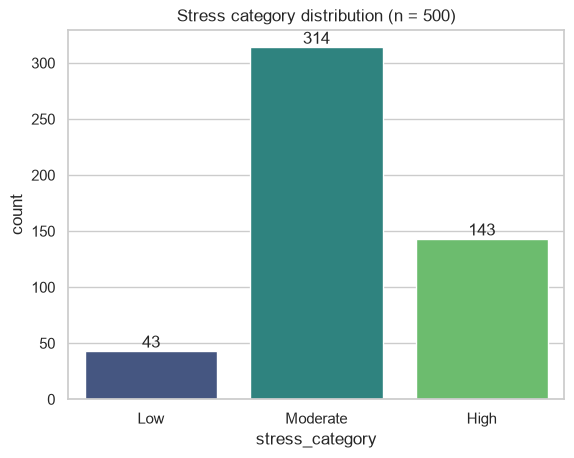

In [4]:
# STEP 3: VISUALISE TARGET
order = ["Low", "Moderate", "High"]
ax = sns.countplot(x="stress_category", data=df, order=order, palette="viridis")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Stress category distribution (n = 500)")
plt.show()

## 4. Features and target

We drop:
* `user_id` — identifier, carries no signal
* `stress_level` — raw score (the target is the category built from it)
* `stress_category` — the target itself
* `happiness_index` — circular (a wellbeing outcome, not a habit)
* `screen_time_group` — derived from `daily_screen_time_hours`

In [5]:
# STEP 4: DEFINE FEATURES AND TARGET
X = df.drop(columns=["user_id", "stress_level", "stress_category",
                     "happiness_index", "screen_time_group"])
y = df["stress_category"]

print("Feature columns:", list(X.columns))
print("Target classes:", y.unique())

Feature columns: ['age', 'gender', 'daily_screen_time_hours', 'sleep_quality', 'days_without_social_media', 'exercise_frequency_per_week', 'social_media_platform']
Target classes: <StringArray>
['Moderate', 'High', 'Low']
Length: 3, dtype: str


## 5. Train/test split (70/30, seed 42)

In [6]:
# STEP 5: TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Majority-class baseline on test set:",
      round(y_test.value_counts(normalize=True).max(), 4))

Training records: 350
Testing records: 150
Majority-class baseline on test set: 0.6133


## 6. Preprocessing — one-hot encoding

`gender` and `social_media_platform` are nominal categories, so they are one-hot encoded (dummy variables). Numeric columns pass through unchanged — decision trees do not need scaling.

In [7]:
# STEP 6: PREPROCESSING PIPELINE (one-hot encode categoricals)
categorical_cols = ["gender", "social_media_platform"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore",
                              sparse_output=False), categorical_cols)
    ],
    remainder="passthrough"
)

def make_model(criterion, max_depth):
    return Pipeline([
        ("prep", preprocessor),
        ("tree", DecisionTreeClassifier(criterion=criterion,
                                        max_depth=max_depth,
                                        random_state=42))
    ])

print("Preprocessor ready")

Preprocessor ready


## 7. Model 1 — Gini, depth 4

In [8]:
# STEP 7: MODEL 1 — gini criterion, max depth 4
model1 = make_model(criterion="gini", max_depth=4)
model1.fit(X_train, y_train)
y_pred1 = model1.predict(X_test)

acc1 = accuracy_score(y_test, y_pred1)
prec1 = precision_score(y_test, y_pred1, average="weighted")
rec1 = recall_score(y_test, y_pred1, average="weighted")
f1_1 = f1_score(y_test, y_pred1, average="weighted")

print("MODEL 1 PERFORMANCE (test set)")
print("Accuracy :", round(acc1, 4))
print("Precision:", round(prec1, 4))
print("Recall   :", round(rec1, 4))
print("F1 Score :", round(f1_1, 4))
print("Train accuracy:", round(model1.score(X_train, y_train), 4))
print()
print(classification_report(y_test, y_pred1))

MODEL 1 PERFORMANCE (test set)
Accuracy : 0.7
Precision: 0.7075
Recall   : 0.7
F1 Score : 0.6703
Train accuracy: 0.7886

              precision    recall  f1-score   support

        High       0.75      0.35      0.48        43
         Low       0.67      0.40      0.50        15
    Moderate       0.69      0.91      0.79        92

    accuracy                           0.70       150
   macro avg       0.70      0.55      0.59       150
weighted avg       0.71      0.70      0.67       150



## 8. Model 2 — Entropy, depth 5

In [9]:
# STEP 8: MODEL 2 — entropy criterion, max depth 5
model2 = make_model(criterion="entropy", max_depth=5)
model2.fit(X_train, y_train)
y_pred2 = model2.predict(X_test)

acc2 = accuracy_score(y_test, y_pred2)
prec2 = precision_score(y_test, y_pred2, average="weighted")
rec2 = recall_score(y_test, y_pred2, average="weighted")
f1_2 = f1_score(y_test, y_pred2, average="weighted")

print("MODEL 2 PERFORMANCE (test set)")
print("Accuracy :", round(acc2, 4))
print("Precision:", round(prec2, 4))
print("Recall   :", round(rec2, 4))
print("F1 Score :", round(f1_2, 4))
print("Train accuracy:", round(model2.score(X_train, y_train), 4))
print()
print(classification_report(y_test, y_pred2))

MODEL 2 PERFORMANCE (test set)
Accuracy : 0.7267
Precision: 0.7217
Recall   : 0.7267
F1 Score : 0.7195
Train accuracy: 0.7943

              precision    recall  f1-score   support

        High       0.68      0.63      0.65        43
         Low       0.67      0.40      0.50        15
    Moderate       0.75      0.83      0.79        92

    accuracy                           0.73       150
   macro avg       0.70      0.62      0.65       150
weighted avg       0.72      0.73      0.72       150



## 9. Model comparison

Model 2 (entropy, depth 5) beats Model 1 on every test metric, so it is used for all remaining outputs.
Both models clearly beat the "always predict Moderate" baseline (61.3%).

                     Model  Accuracy  Precision  Recall  F1 Score
   Model 1 (gini, depth 4)    0.7000     0.7075  0.7000    0.6703
Model 2 (entropy, depth 5)    0.7267     0.7217  0.7267    0.7195
Baseline (always Moderate)    0.6133        NaN     NaN       NaN


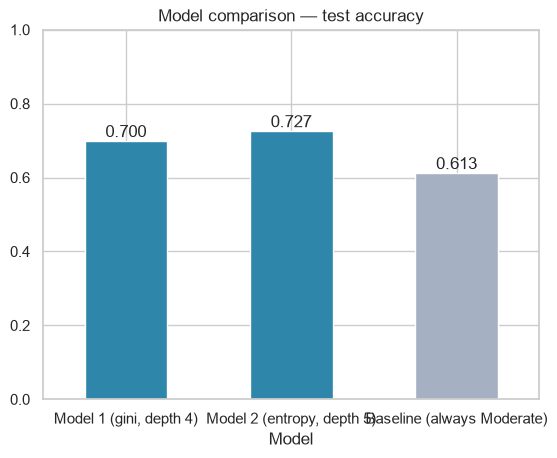

In [10]:
# STEP 9: MODEL COMPARISON
comparison = pd.DataFrame({
    "Model": ["Model 1 (gini, depth 4)", "Model 2 (entropy, depth 5)", "Baseline (always Moderate)"],
    "Accuracy": [round(acc1, 4), round(acc2, 4), round(y_test.value_counts(normalize=True).max(), 4)],
    "Precision": [round(prec1, 4), round(prec2, 4), None],
    "Recall": [round(rec1, 4), round(rec2, 4), None],
    "F1 Score": [round(f1_1, 4), round(f1_2, 4), None],
})
print(comparison.to_string(index=False))

ax = comparison.drop(columns=["Precision", "Recall", "F1 Score"]).plot(
    x="Model", y="Accuracy", kind="bar", legend=False, color=["#2e86ab", "#2e86ab", "#a5b1c2"])
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Model comparison — test accuracy")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

# Best model for all further analysis
best_model = model2
y_pred_best = y_pred2

## 10. Confusion matrix (best model)

                 Pred High  Pred Low  Pred Moderate
Actual High             27         0             16
Actual Low               0         6              9
Actual Moderate         13         3             76


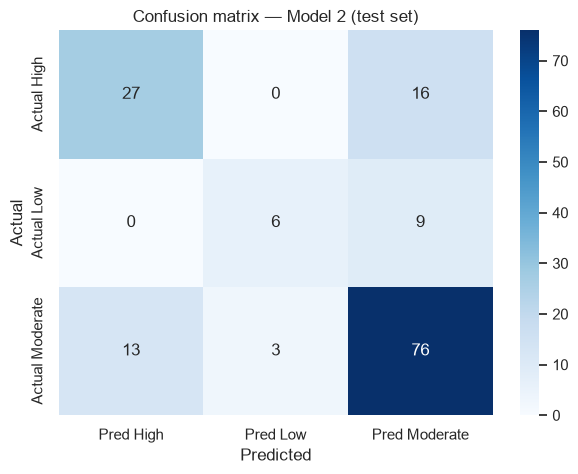

In [11]:
# STEP 10: CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred_best)
cm_table = pd.DataFrame(
    cm,
    index=["Actual High", "Actual Low", "Actual Moderate"],
    columns=["Pred High", "Pred Low", "Pred Moderate"],
)
print(cm_table)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_table, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — Model 2 (test set)")
plt.show()

## 11. Decision tree visualisation

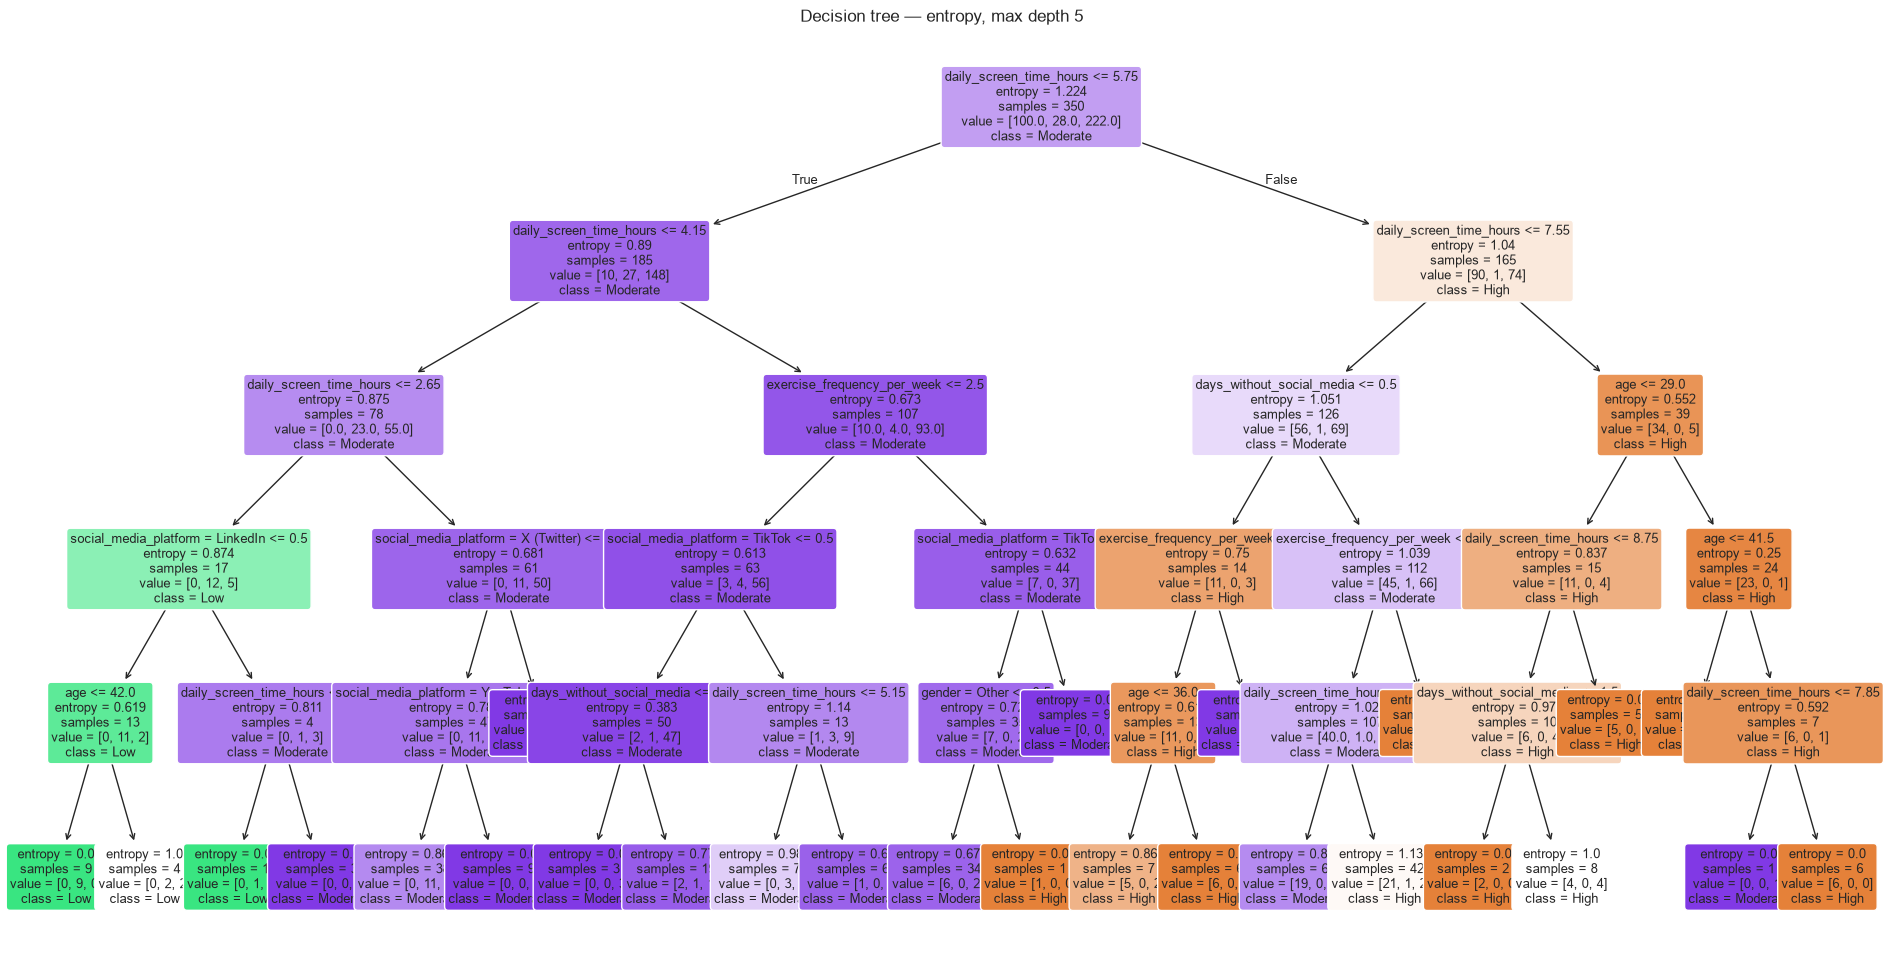

Tree depth: 5
Leaf nodes: 26


In [12]:
# STEP 11: PLOT THE TREE
def pretty_feature(name):
    if name.startswith("remainder__"):
        return name.replace("remainder__", "")
    for col in ["gender", "social_media_platform"]:
        prefix = f"cat__{col}_"
        if name.startswith(prefix):
            return f"{col} = {name[len(prefix):]}"
    return name

feature_names = [pretty_feature(n) for n in
                 best_model.named_steps["prep"].get_feature_names_out()]

plt.figure(figsize=(24, 12))
plot_tree(best_model.named_steps["tree"],
          feature_names=feature_names,
          class_names=["High", "Low", "Moderate"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision tree — entropy, max depth 5")
plt.show()

print("Tree depth:", best_model.named_steps["tree"].get_depth())
print("Leaf nodes:", best_model.named_steps["tree"].get_n_leaves())

## 12. Feature importance

 Rank                             Feature  Importance
    1             daily_screen_time_hours    0.736684
    2         exercise_frequency_per_week    0.066008
    3           days_without_social_media    0.052103
    4                                 age    0.048585
    5      social_media_platform = TikTok    0.032038
    6 social_media_platform = X (Twitter)    0.020620
    7     social_media_platform = YouTube    0.017395
    8    social_media_platform = LinkedIn    0.015845
    9                      gender = Other    0.010722
   10                       gender = Male    0.000000
   11   social_media_platform = Instagram    0.000000
   12                       sleep_quality    0.000000


/var/folders/dd/wck9v_55587d1bv52lzk0j800000gn/T/ipykernel_77407/429519540.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x="Importance", y="Feature", palette="viridis")


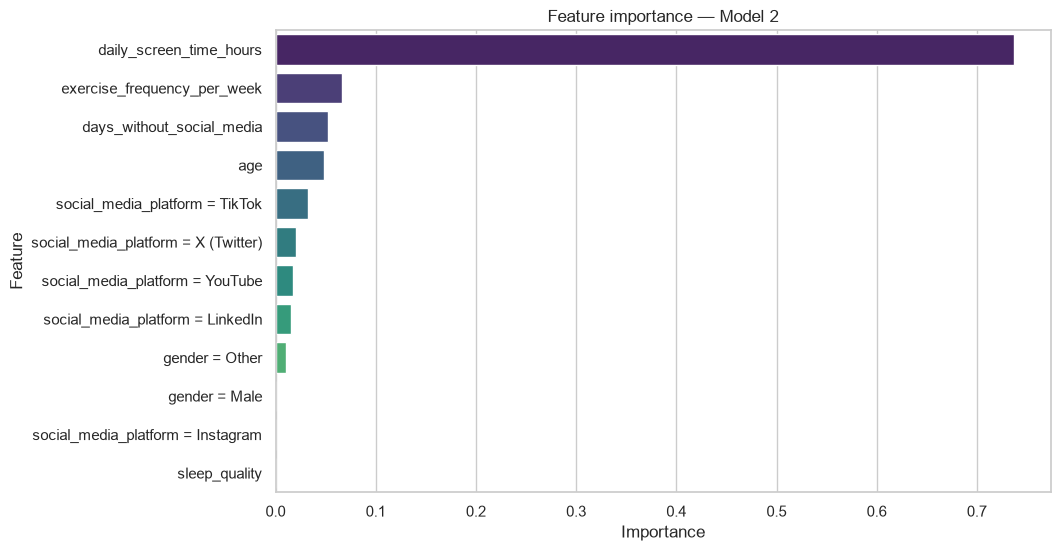

In [13]:
# STEP 12: FEATURE IMPORTANCE
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_model.named_steps["tree"].feature_importances_,
}).sort_values("Importance", ascending=False).reset_index(drop=True)
importance_df["Rank"] = importance_df.index + 1
importance_df = importance_df[["Rank", "Feature", "Importance"]]

print(importance_df.to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature", palette="viridis")
plt.title("Feature importance — Model 2")
plt.show()

## 13. What the tree actually says

Screen time carries **73.7%** of the model's importance — every path in the tree starts with a screen-time question.

**The top rules**
* **Screen time ≤ 2.65 hrs/day → Low stress.** The lightest users are almost always predicted Low.
* **2.65 – 5.75 hrs/day → Moderate** across nearly every branch.
* **Above 5.75 hrs/day → High stress dominates:**
  * 5.75–7.55 hrs with no social-media-free days and ≤ 4.5 exercise sessions/week → **High**
  * 5.75–7.55 hrs with **more than 4.5 exercise sessions/week → Moderate** ← exercise appears to moderate the effect
  * 6.75–7.55 hrs (when users do take social-media breaks) → **High**
  * ≥ 7.55 hrs → **High** in almost every branch (only users 42+ in the narrow 7.55–7.85 band are predicted Moderate)

**What this means**
The tree independently finds the pattern we suspected from the EDA: heavier screen time is associated with higher reported stress, while exercise frequency acts as a protective factor in the moderate-heavy band. Platform and gender barely matter — the strongest signal is how long people are online.

## 14. Key takeaways & limitations

**Key takeaways**
* Habits alone (no happiness score) classify stress at **72.7%** test accuracy — about **11 points above** the majority-class baseline (61.3%).
* Screen time is by far the most informative feature; exercise is a modest protective factor.
* This accuracy is honest: dropping `happiness_index` cost ~2 accuracy points compared with the earlier version, but the model now genuinely answers the research question.

**Limitations**
* **Class imbalance:** only 43/500 users (8.6%) are Low-stress; the model's recall for Low is just 0.40 — it often confuses Low with Moderate.
* **Small, self-reported dataset:** 500 rows, 1–10 self-ratings; our Low/Moderate/High cut-offs (≤4 / 5–7 / ≥8) are a modelling choice.
* **Shallow tree:** depth 5 simplifies reality; interactions are only captured roughly.
* **Instability:** decision trees vary with the data split (fixed here with `random_state=42`).
* **Slight overfitting:** train accuracy 79.4% vs test 72.7% — normal for trees on small data.

## 15. Export results

In [14]:
# STEP 15: EXPORT TABLES (CSV + Excel + rules)
predictions = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_best,
}).reset_index(drop=True)

comparison.to_csv("decision_tree_performance_table.csv", index=False)
cm_table.to_csv("decision_tree_confusion_matrix.csv")
importance_df.to_csv("decision_tree_feature_importance.csv", index=False)

with pd.ExcelWriter("Decision_Tree_Report_Tables.xlsx") as writer:
    comparison.to_excel(writer, sheet_name="Model_Comparison", index=False)
    cm_table.to_excel(writer, sheet_name="Confusion_Matrix")
    importance_df.to_excel(writer, sheet_name="Feature_Importance", index=False)
    predictions.to_excel(writer, sheet_name="Predictions", index=False)

tree_rules = export_text(best_model.named_steps["tree"],
                         feature_names=feature_names)
with open("decision_tree_rules.txt", "w") as f:
    f.write(tree_rules)

print("Exported: decision_tree_performance_table.csv, "
      "decision_tree_confusion_matrix.csv, decision_tree_feature_importance.csv, "
      "Decision_Tree_Report_Tables.xlsx, decision_tree_rules.txt")
print()
print("Prediction sample (first 10):")
print(predictions.head(10).to_string(index=False))

Exported: decision_tree_performance_table.csv, decision_tree_confusion_matrix.csv, decision_tree_feature_importance.csv, Decision_Tree_Report_Tables.xlsx, decision_tree_rules.txt

Prediction sample (first 10):
  Actual Predicted
Moderate  Moderate
Moderate  Moderate
Moderate      High
Moderate  Moderate
Moderate      High
Moderate  Moderate
    High      High
Moderate  Moderate
Moderate  Moderate
    High      High
